# The Provincial Bird: Is It the Rain?

My A2 report found that some Winnipeg summers are many times buggier than others: 2016 averaged
28 mosquitoes per trap per count day, 2017 only 3. It also
found the peak usually comes in June or July, and that no side of the city escapes. So the bigger question: **which
summers were the worst, and is a wet spring to blame?**

Data: City of Winnipeg trap counts (my A2 data) and Environment Canada daily weather at The Forks, joined on date.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import mosquito_tools as tools

# Settings: change these, not the code below
SEASONS_FILE = "../data/clean/seasons.csv"
DAILY_FILE = "../data/clean/daily.csv"
WET_SPRING_MM = 150             # May and June rain that counts as a wet spring
SIDES = {"north_west": "North West", "north_east": "North East",   # trap columns and their names
         "south_east": "South East", "south_west": "South West"}

In [2]:
seasons = pd.read_csv(SEASONS_FILE, parse_dates=["peak_date"]).set_index("year")
daily = pd.read_csv(DAILY_FILE, parse_dates=["date"])
first_year, last_year = seasons.index.min(), seasons.index.max()

## Chapter 1: Which summers were the worst?

Counts are taken on 59 to 118 days a summer, so the fair comparison is the **average per
count day**, not the total.

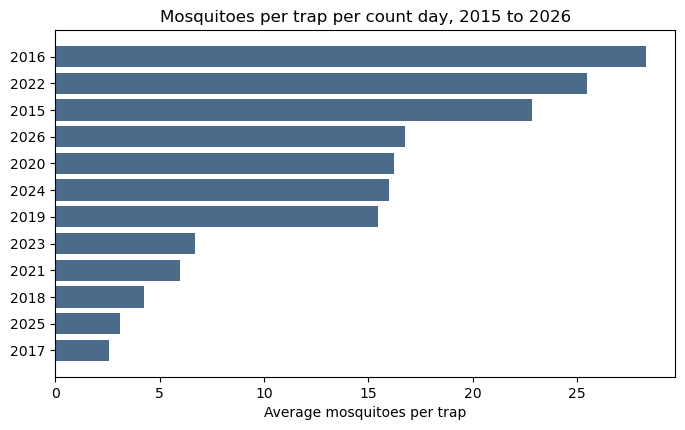

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
tools.ranked_bars(ax, seasons["season_avg"], f"Mosquitoes per trap per count day, {first_year} to {last_year}",
                  "Average mosquitoes per trap")
plt.show()

**What it shows:** 2016 was the worst summer (28 per trap per count day), and
2017 the quietest (3). But the worst single **day** was August 29,
2022, at 235 per trap. **What it might mean:** a bad summer and a bad day aren't the same thing.
**What it doesn't show:** what made the bad summers bad.

If it isn't one bad day, is it the time of year, or the part of town?

## Chapter 2: When, and where?

peak_date
June         5
July         5
August       1
September    1
Name: count, dtype: int64


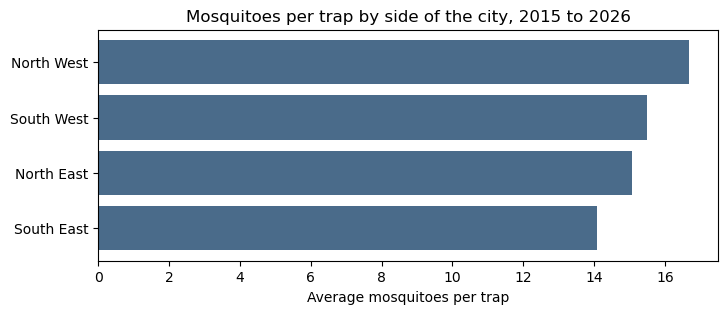

In [4]:
print(seasons["peak_date"].dt.month_name().value_counts())
sides = tools.side_averages(daily, SIDES)
fig, ax = plt.subplots(figsize=(8, 3))
tools.ranked_bars(ax, sides, f"Mosquitoes per trap by side of the city, {first_year} to {last_year}",
                  "Average mosquitoes per trap")
plt.show()

**What it shows:** 9 of 11 summers peaked in June or July. The North West averages
16.6 per trap and the South East 13.6. **What it might mean:** the timing is predictable, and the
geography barely matters: about three mosquitoes per trap is not enough to move for. **What it doesn't show:** why
some Junes are so much worse than others.

The city is the same every year. The weather isn't. Is it the spring rain?

## Chapter 3: Is it the rain?

Mosquitoes breed in standing water, so the guess is that a wet May and June fills the ponds for the summer. Each dot
is a summer; "wet" means 150 mm of rain or more in May and June.

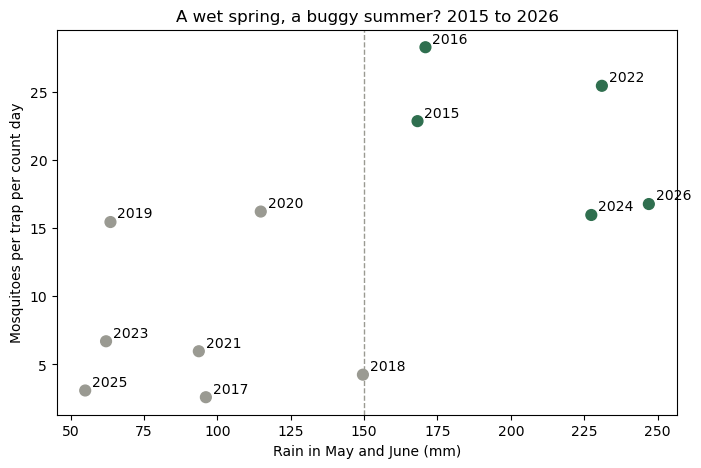

In [5]:
wet = tools.is_wet(seasons, WET_SPRING_MM)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(seasons["spring_precip_mm"], seasons["season_avg"], c=wet.map({True: "#2f6f4f", False: "#9a9a92"}), s=60)
for year, row in seasons.iterrows():
    ax.annotate(str(year), (row["spring_precip_mm"], row["season_avg"]), xytext=(5, 3), textcoords="offset points")
ax.axvline(WET_SPRING_MM, color="#9a9a92", linestyle="--", linewidth=1)
ax.set_title(f"A wet spring, a buggy summer? {first_year} to {last_year}")
ax.set_xlabel("Rain in May and June (mm)")
ax.set_ylabel("Mosquitoes per trap per count day")
plt.show()

**What it shows:** the four wet springs were four of the five buggiest summers,
which averaged 23 mosquitoes per trap against 8 in drier years (a correlation of
0.66). The wettest spring, 2022 (231 mm), brought the worst day on record.
**What it might mean:** a wet spring is a good warning. **What it doesn't show:** that rain is the only cause.

## Key numbers

Every number the story quotes comes from here. After a rerun, read the story against this cell.

In [6]:
tools.key_numbers(seasons, daily, WET_SPRING_MM, SIDES)

summers                                                     2015 to 2026 (12)
count days per summer                                               59 to 118
worst summer                                             2016 (28.3 per trap)
quietest summer                                           2017 (2.6 per trap)
worst day                                           2022-08-29 (235 per trap)
peaks in June or July                                                10 of 12
buggiest side                                               North West (16.7)
quietest side                                               South East (14.1)
wet springs                         5, 4 of them in the five buggiest summers
wet vs dry summers                                       21.9 vs 7.8 per trap
rain and mosquitoes, correlation                                         0.63
wettest spring                                                  2026 (247 mm)
its summer                                     rank 4, average 1